# Statistical Moments

Companion notebook for the [statistical moments note](../../notes/random_variables_and_distributions/statistical_moments.md) and its [exercises](../../exercises/random_variables_and_distributions/statistical_moments.md).

* Raw moment: $\mu'_n=E[X^n]$; central moment: $\mu_n=E[(X-\mu)^n]$.
* Variance $=\mu_2$; skewness $=\mu_3/\sigma^3$; excess kurtosis $=\mu_4/\sigma^4-3$.
* MGF: $M_X(t)=E[e^{tX}]$, with $E[X^n]=M_X^{(n)}(0)$.

In [1]:
import math

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

## Moments of a small pmf

For $X\in\{0,1,2\}$ with probabilities $0.2,0.5,0.3$ we compute raw and central moments directly from the definitions. The third central moment is slightly negative, so the distribution is mildly left-skewed.

In [2]:
x = np.array([0, 1, 2])
p = np.array([0.2, 0.5, 0.3])

mean = (x * p).sum()
raw2 = (x**2 * p).sum()
var = ((x - mean) ** 2 * p).sum()
mu3 = ((x - mean) ** 3 * p).sum()
print(f"E[X] = {mean:.3f}, E[X^2] = {raw2:.3f}, Var = {var:.3f} (= E[X^2]-E[X]^2 = {raw2 - mean**2:.3f})")
print(f"third central moment = {mu3:.4f}, skewness = {mu3 / var**1.5:.4f}")

E[X] = 1.100, E[X^2] = 1.700, Var = 0.490 (= E[X^2]-E[X]^2 = 0.490)
third central moment = -0.0480, skewness = -0.1399


## Skewness and kurtosis of samples

Gamma(4, 1) is right-skewed (theoretical skewness $2/\sqrt{\alpha}=1$) and has positive excess kurtosis ($6/\alpha=1.5$); the normal has both equal to 0. In a right-skewed sample the mean exceeds the median.

gamma(4,1)   skew  1.014  excess kurtosis  1.591  mean 4.002  median 3.670
normal(6,2)  skew  0.012  excess kurtosis  0.013  mean 6.003  median 6.002


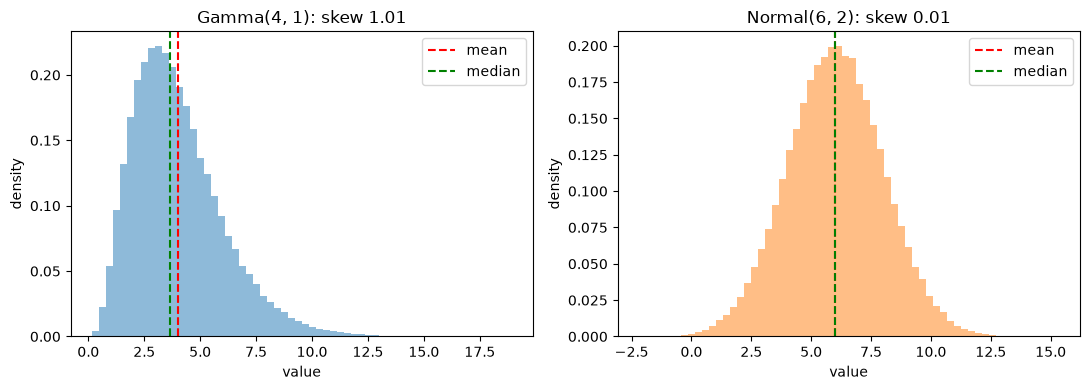

In [3]:
gamma_sample = rng.gamma(4, 1, size=100_000)
normal_sample = rng.normal(6, 2, size=100_000)

for name, s in [("gamma(4,1)", gamma_sample), ("normal(6,2)", normal_sample)]:
    print(f"{name:12s} skew {stats.skew(s):6.3f}  excess kurtosis {stats.kurtosis(s):6.3f}  "
          f"mean {s.mean():.3f}  median {np.median(s):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for axis, s, c, title in [(ax[0], gamma_sample, "C0", "Gamma(4, 1)"), (ax[1], normal_sample, "C1", "Normal(6, 2)")]:
    axis.hist(s, bins=60, density=True, color=c, alpha=0.5)
    axis.axvline(s.mean(), color="red", linestyle="--", label="mean")
    axis.axvline(np.median(s), color="green", linestyle="--", label="median")
    axis.set(title=f"{title}: skew {stats.skew(s):.2f}", xlabel="value", ylabel="density")
    axis.legend()
plt.tight_layout()
plt.show()

## The moment-generating function of an exponential

For $X\sim\text{Exp}(1)$, $M_X(t)=1/(1-t)$ for $t<1$. The Monte Carlo estimate $\hat M(t)=\frac1N\sum e^{tX_i}$ is unbiased but its variance grows quickly as $t$ approaches $1$ (the variance of $e^{tX}$ is finite only for $t<0.5$).

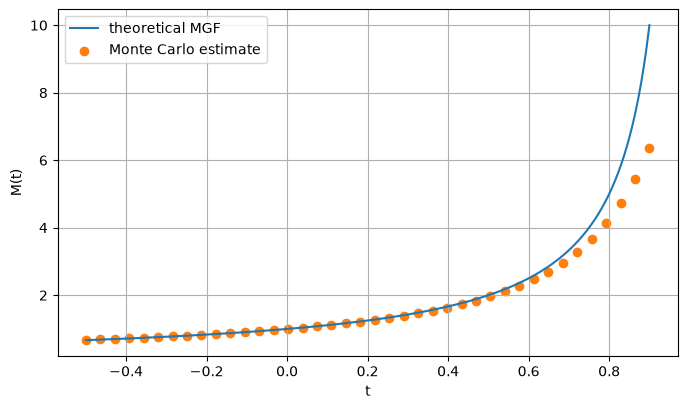

worst relative error for t <= 0.3: 0.0099


In [4]:
lam = 1.0
samples = rng.exponential(1 / lam, size=10_000)
t_emp = np.linspace(-0.5, 0.9, 40)
t_curve = np.linspace(-0.5, 0.9, 400)
m_hat = np.array([np.exp(t * samples).mean() for t in t_emp])

plt.figure(figsize=(8, 4.5))
plt.plot(t_curve, lam / (lam - t_curve), label="theoretical MGF")
plt.scatter(t_emp, m_hat, color="C1", label="Monte Carlo estimate")
plt.xlabel("t")
plt.ylabel("M(t)")
plt.legend()
plt.grid(True)
plt.show()

print("worst relative error for t <= 0.3:",
      np.max(np.abs(m_hat[t_emp <= 0.3] / (lam / (lam - t_emp[t_emp <= 0.3])) - 1)).round(4))

## Moments from derivatives of the MGF

Differentiating $M(t)=\lambda/(\lambda-t)$ gives $E[X^n]=n!/\lambda^n$. We confirm the first three moments with central finite differences of the exact MGF at $t=0$ and compare with sample moments.

In [5]:
lam = 2.0
M = lambda t: lam / (lam - t)
h = 1e-3
d1 = (M(h) - M(-h)) / (2 * h)
d2 = (M(h) - 2 * M(0) + M(-h)) / h**2
d3 = (M(2 * h) - 2 * M(h) + 2 * M(-h) - M(-2 * h)) / (2 * h**3)

s = rng.exponential(1 / lam, size=500_000)
print(f"{'n':>2} {'finite diff':>12} {'n!/lam^n':>10} {'sample':>9}")
for n, fd in zip((1, 2, 3), (d1, d2, d3)):
    print(f"{n:>2} {fd:12.4f} {math.factorial(n) / lam**n:10.4f} {np.mean(s**n):9.4f}")

 n  finite diff   n!/lam^n    sample
 1       0.5000     0.5000    0.4999
 2       0.5000     0.5000    0.4992
 3       0.7500     0.7500    0.7467


## Variance as a moment of inertia

Treat each observation as a unit mass. The mean-squared distance from the center of mass is the variance (the moment of inertia per unit mass), and it is smallest about the mean (parallel-axis theorem): $I_c=I_0-N\bar x^2$.

I about 0 = 10.000, I about the mean 0.667 = 8.667, I0 - N*xbar^2 = 8.667


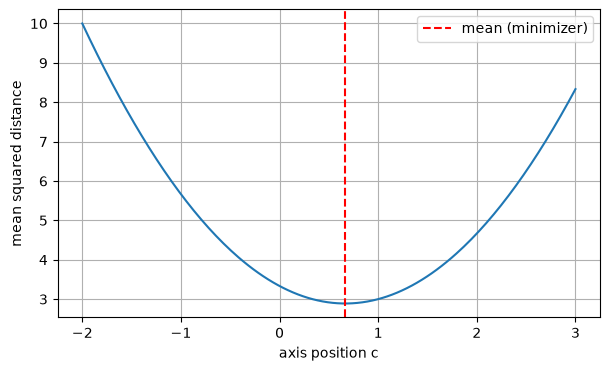

In [6]:
pts = np.array([-1.0, 0.0, 3.0])
xbar = pts.mean()
I0 = (pts**2).sum()
Ic = ((pts - xbar) ** 2).sum()
print(f"I about 0 = {I0:.3f}, I about the mean {xbar:.3f} = {Ic:.3f}, I0 - N*xbar^2 = {I0 - len(pts) * xbar**2:.3f}")

# Moment of inertia (mean squared deviation) as a function of the axis position
c = np.linspace(-2, 3, 200)
inertia = ((pts[:, None] - c) ** 2).mean(axis=0)
plt.figure(figsize=(7, 4))
plt.plot(c, inertia)
plt.axvline(xbar, color="red", linestyle="--", label="mean (minimizer)")
plt.xlabel("axis position c")
plt.ylabel("mean squared distance")
plt.legend()
plt.grid(True)
plt.show()

## Two dimensions: covariance eigenvalues (PCA)

For 2-D data the covariance matrix plays the role of the inertia tensor. Its eigenvectors are the principal axes and the eigenvalues are the variances along them.

eigenvalues (variances along principal axes): [0.109 3.806]


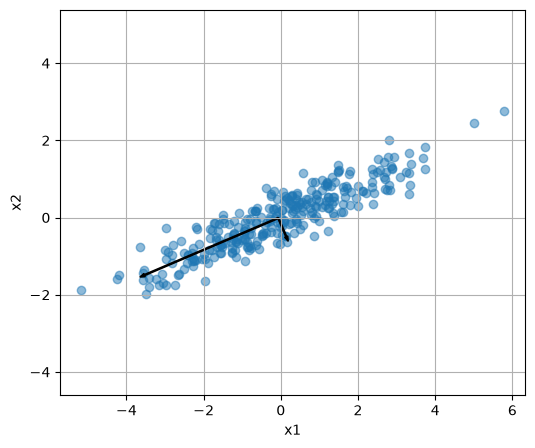

In [7]:
cov = np.array([[3.0, 1.2], [1.2, 0.6]])
data = rng.multivariate_normal([0, 0], cov, size=300)
sample_cov = np.cov(data.T)
vals, vecs = np.linalg.eigh(sample_cov)
print("eigenvalues (variances along principal axes):", vals.round(3))

plt.figure(figsize=(6, 5))
plt.scatter(data[:, 0], data[:, 1], alpha=0.5)
mu = data.mean(axis=0)
for v, vec in zip(vals, vecs.T):
    plt.arrow(mu[0], mu[1], *(2 * np.sqrt(v) * vec), color="k", width=0.03, length_includes_head=True)
plt.axis("equal")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True)
plt.show()

## Takeaways

* Variance, skewness and kurtosis are standardized central moments of order 2, 3 and 4.
* The MGF packages all raw moments: $E[X^n]=M^{(n)}(0)$.
* Variance is a moment of inertia and PCA is the principal-axes problem for the covariance matrix.